# Codec Test Pipeline

In [22]:
# imports
from pathlib import Path
from PIL import Image
from codec import Codec, RLE, ZigZag, DCT, Quantisation
import numpy as np
import matplotlib.pyplot as plt
import random
import hashlib
import json
from numpy import uint8

## Section 1: Input Output Contracts



- Codec for compression and decompression, accepts a Pillow image or Numpy array
- The shape accepted by codec can be of form (height, width) or (height, width, channels). Thus both 2D and 3D inputs are accepted.
- Height, width and no. of channels must be greater than zero
- The dtype must be uint8 with pixel values between [0,255]
- The MVTEC AD dataset images are PNG images, they are first converted to RGB images to obtain the raw image.
- Decompression returns an array with same shape and dtype as input given to compression method.
- The input method configures the settings dictionary required by test_pipeline method. It takes following parameters:
    - read_img: Set true to read image path from user (Default: False)
    - test: Set true to test Codec on fixed testing inputs (Default: False)
    - read_output_dir_path: Set true to read output directory from user (Default: False, output_dir="curr_dir/compressed_images/")
    - read_q_step: Set true to read quantisation step from user (Default: False, q_step=32)
    - read_block_size: Set true to read block size from user (Default: False, block_size=8)
- The 'settings' dictionary consists of following values:
    - img_path: Path of the image
    - output_dir: Path of directory where compressed file will be saved
    - q_step: Quantisation step
    - block_size: Block size
- The test_pipeline method takes the above settings as input. 
- The test_pipeline method also accepts two optional parameters:
    - Image (pass raw image instead of image path)
    - Output_filename (pass the desired name of the compressed file)
- The test_pipeline exhibit the following:
    - Display the raw image
    - Compress the image using Codec
    - Decompress the image using Codec
    - Display the decompressed image
    - Display the following stats:
        - Block size used by Codec
        - Quantisation step used by Codec
        - Raw image size
        - Compressed file size
        - Compression ratio: Raw to compressed image ratio
        - Bits per pixel
        - Mean squared error
        - PSNR

## Section 2: A quality-assurance report: missing values, ranges, duplicates, corrupt files.


### 2.1 Load the Dataset image paths

In [24]:
rdir = "../mvtec_dataset"
object_dir = Path(rdir)
all_img_paths = []

for imgpath in object_dir.iterdir():
    if not imgpath.is_file():
        continue
    all_img_paths.append(imgpath)

if not all_img_paths:
    raise ValueError("No images found in the dataset folder.")

### 2.2 Dataset quality checks

Check for any corrupt or duplicate images in the dataset. Record the shape, data type and range of all images.

In [25]:
# check for corrupt images, image shape, image dtype, minimum and maximum pixel value
corrupt_imgs = []
image_shape_set = set()
image_dtype_set = set()
min_value = np.inf
max_value = -1

for imgpath in all_img_paths:
    try:
        with Image.open(imgpath) as img:
            img.load()
            pixels = np.asarray(img)
            min_value = min(min_value, pixels.min())
            max_value = max(max_value, pixels.max())
            image_shape_set.add(pixels.shape)
            image_dtype_set.add(str(pixels.dtype))
    except (OSError, ValueError) as error:
        corrupt_imgs.append(imgpath)
        print(f"Cannot read image path: {imgpath}: {error}")

l_all_img_paths = len(all_img_paths)
l_corrupt_imgs = len(corrupt_imgs)

print(f"Total images checked: {l_all_img_paths}")
print(f"Valid images found: {l_all_img_paths-l_corrupt_imgs}")
print(f"Corrupt images found: {l_corrupt_imgs}")

print("Verify image shape, type and range:")
print(f"Image shapes: {sorted(image_shape_set)}")
print(f"Image dtype: {sorted(image_dtype_set)}")
print(f"Image pixel values range from {min_value} to {max_value}")

# Check for duplicates by computing hashes of the image
img_hashes = {}
duplicate_images = []
for img_path in all_img_paths:
    # skip the corrupt images from duplicate check
    if img_path in corrupt_imgs:  
        continue
    
    digest = hashlib.sha256(img_path.read_bytes()).hexdigest()
    
    if digest in img_hashes:
        duplicate_images.append((img_hashes[digest],img_path.name))
    else:
        img_hashes[digest] = img_path.name

print(f"Number of duplicate images: {len(duplicate_images)}")
if len(duplicate_images) > 0:
    print('Following are the duplicate images:')
    for first, second in duplicate_images:
        print(f"{second} is identical to {first}")

Total images checked: 1189
Valid images found: 1189
Corrupt images found: 0
Verify image shape, type and range:
Image shapes: [(700, 700, 3), (800, 800, 3), (1000, 1000, 3), (1024, 1024, 3)]
Image dtype: ['uint8']
Image pixel values range from 3 to 255
Number of duplicate images: 0


## Section 3: Independent manifest: relative path, byte size, SHA-256 digest 

Save the relative paths, size in bytes and SHA256 digest to dataset_manifest.json file.

In [26]:
manifest_path = Path("dataset_manifest.json")

if manifest_path.exists():
    print("Manifest file alreadys exists. No new file created")
else:
    manifests = []
    for img_path in all_img_paths:
        manifests.append({
            "path": img_path.relative_to(object_dir).as_posix(),
            "size_bytes": img_path.stat().st_size,
            "sha256": hashlib.sha256(img_path.read_bytes()).hexdigest()
        })
        
    with manifest_path.open("w", encoding="utf-8") as file:
        json.dump(manifests, file, indent=2)
        
    print("Created and saved manifest file.")

Manifest file alreadys exists. No new file created


## Section 4: Testing: Entry point for testing the pipeline

Following section consists of test_pipeline method, other supplementary functions and testing scenarios.

### 4.1 Get one random image path from the dataset

Pick a random image from the dataset.

In [27]:
def get_random_image():
    return random.choice(all_img_paths)

### 4.2 Display Image function

In [28]:
def display_image(img, cmap: str = None, title: str = None, 
                  axes: bool = True, figsize=(4, 4),
                  xlabel: str = None, ylabel: str = None, xticks: list = None, yticks: list = None, ax=None):
    
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
        
    ax.imshow(img, cmap=cmap)

    if title is not None:
        ax.set_title(title)

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    if not axes:
        ax.axis('off')
        
    if xticks is not None:
        ax.set_xticks(xticks)
        
    if yticks is not None:
        ax.set_yticks(yticks)
        
    return ax

### 4.3 Read Inputs from User
Reads required inputs from the users based on the input knobs or set them to default, to configure the settings.

In [29]:
def inputs(read_img = False, test = False, read_output_dir_path = False, read_q_step = False, read_block_size = False):
    
    inputs = {}
    
    # read the image path
    if read_img:
        img_path = Path(input("Enter the image path: ").strip()).expanduser()

        if not img_path.is_file():
            raise FileNotFoundError(f"Image not found: {img_path}")
        inputs["img_path"] = img_path
    elif test:
        pass 
    else:
        img_path = get_random_image()
        inputs["img_path"] = img_path
    
    # rad the folder input where compressed images will be stored
    while read_output_dir_path:
        try:
            folder_text = input("Enter the output folder: ").strip()

            if not folder_text:
                raise ValueError("The folder path cannot be empty.")
            
            break

        except (OSError, ValueError, RuntimeError) as error:
            print(f"Cannot use this folder: {error}")
            print("Please enter another folder path.")
            
    if not read_output_dir_path:
        folder_text = "compressed_images"
    output_dir = Path(folder_text).expanduser()
    output_dir.mkdir(parents=True, exist_ok=True)
    inputs["output_dir"] = output_dir
    
    # read the block size input
    while read_block_size:
        try:
            block_size = int(input("Enter block size (positive integer e.g. 8): "))

            if block_size <= 0:
                raise ValueError

            break

        except ValueError:
            print("Enter a valid block size.")
    if not read_block_size:
        block_size = 8
    inputs["block_size"] = block_size

    # read the q_step input
    while read_q_step:
        try:
            q_step = int(input("Enter value for quantisation step (e.g. 32): "))

            if q_step <= 0:
                raise ValueError

            break
        
        except ValueError:
            print("Invalid q_step. Enter a positive integer like 8 or 32.")
    if not read_q_step:
        q_step = 32
    inputs["q_step"] = q_step
    
    return inputs


### 4.4 Codec testing pipeline setup

Final test pipeline which takes setting input and perform the compression and decompression on image using Codec.

In [30]:
def test_pipeline(settings, image=None, output_filename=None):
    
    # unpack inputs
    img_path = settings["img_path"]
    output_dir = settings["output_dir"]
    q_step = settings["q_step"]
    block_size = settings["block_size"]

    # get image array
    if image is not None:
        img_array = image
        if output_filename is None:
            output_filename = "image_compressed.json"
    else:
        with Image.open(img_path) as source:
            img = source.convert("RGB")

        img_array = np.asarray(img)
        
        if output_filename is None:
            output_filename = f"{img_path.stem}_compressed.json"

    # configure Codec
    codec = Codec(stages=[DCT(), Quantisation(q_steps=q_step), ZigZag(), RLE()], block_size=block_size, output_dir=output_dir,)

    # perform compression
    codec.compress(img_array, output_file=output_filename)

    # verify compressed image was created
    compressed_file_path = codec.output_dir / f"{output_filename}"

    if not compressed_file_path.is_file():
        raise FileNotFoundError("Compressed file was not created")

    if compressed_file_path.stat().st_size == 0:
        raise ValueError("Compressed file is empty")

    print("PASS: The compressed file exists.")
    print("PASS: The compressed file is not empty.")

    # perform decompression
    with compressed_file_path.open('r', encoding="utf-8") as file:
        compressed_image = json.load(file)

    decompressed_image = codec.decompress(compressed_image)

    # verify decompressed image shape and type
    assert decompressed_image.shape == img_array.shape
    assert decompressed_image.dtype == img_array.dtype
    
    # display original image
    print("Selected Image: ")
    display_image(img, axes=False)
    plt.show()

    # display the reconstructed image
    display_image(Image.fromarray(decompressed_image), axes=False)
    plt.show()

    # calculate statistics
    raw_image_size = img_array.nbytes
    compressed_image_size = compressed_file_path.stat().st_size

    height, width = img_array.shape[:2]
    bits_per_pixel = compressed_image_size * 8 / (height * width)
    compression_ratio = raw_image_size / compressed_image_size

    difference = (img_array.astype(np.float64) - decompressed_image.astype(np.float64))
    mse = float(np.mean(difference ** 2))
    psnr = np.inf if mse == 0 else 10 * np.log10(255**2 / mse)

    # display the stats
    print("Statistics:")
    print(f"Block size: {block_size}")
    print(f"Quantisation step: {q_step}")
    print(f"Raw image size: {raw_image_size} bytes")
    print(f"Compressed file size: {compressed_image_size} bytes")
    print(f"Raw to compressed image ratio: {compression_ratio}")
    print(f"Bits per pixel: {bits_per_pixel}")
    print(f"Mean squared error: {mse}")
    print(f"PSNR: {psnr}")


### 4.5 Our Testing Images

Encoded image saved to: compressed_images/008_capsule_compressed.json
PASS: The compressed file exists.
PASS: The compressed file is not empty.
Selected Image: 


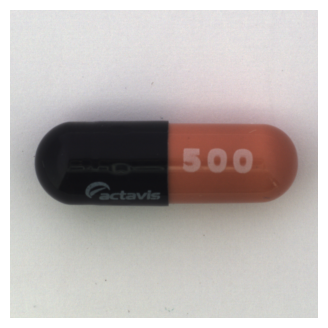

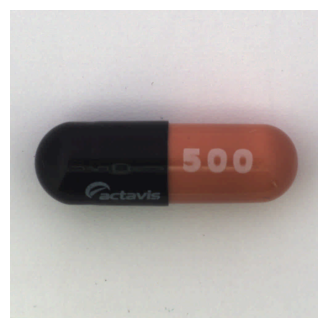

Statistics:
Block size: 8
Quantisation step: 32
Raw image size: 3000000 bytes
Compressed file size: 981161 bytes
Raw to compressed image ratio: 3.057602167228416
Bits per pixel: 7.849288
Mean squared error: 9.192177
PSNR: 38.49661982548081
Encoded image saved to: compressed_images/079_hazelnut_compressed.json
PASS: The compressed file exists.
PASS: The compressed file is not empty.
Selected Image: 


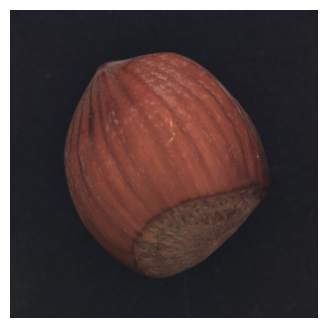

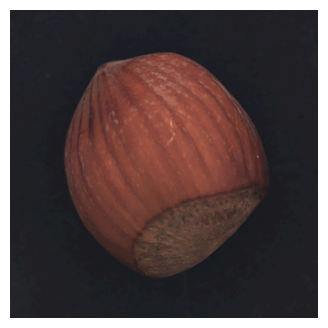

Statistics:
Block size: 8
Quantisation step: 32
Raw image size: 3145728 bytes
Compressed file size: 1096603 bytes
Raw to compressed image ratio: 2.8686115212159735
Bits per pixel: 8.366416931152344
Mean squared error: 7.027783393859863
PSNR: 39.66261993403374
Encoded image saved to: compressed_images/143_metal_nut_compressed.json
PASS: The compressed file exists.
PASS: The compressed file is not empty.
Selected Image: 


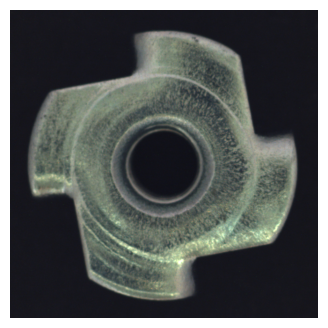

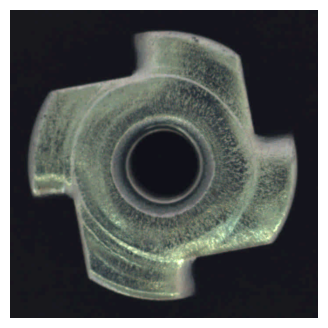

Statistics:
Block size: 8
Quantisation step: 32
Raw image size: 1470000 bytes
Compressed file size: 812855 bytes
Raw to compressed image ratio: 1.8084406197907377
Bits per pixel: 13.271102040816327
Mean squared error: 15.50754761904762
PSNR: 36.22537237440201
Encoded image saved to: compressed_images/200_pill_compressed.json
PASS: The compressed file exists.
PASS: The compressed file is not empty.
Selected Image: 


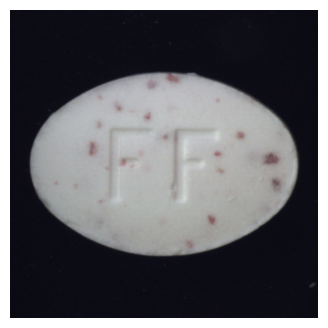

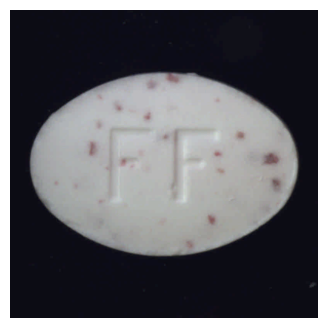

Statistics:
Block size: 8
Quantisation step: 32
Raw image size: 1920000 bytes
Compressed file size: 656686 bytes
Raw to compressed image ratio: 2.9237717874296085
Bits per pixel: 8.208575
Mean squared error: 5.4081296875
PSNR: 40.800332633836085
Encoded image saved to: compressed_images/058_transistor_compressed.json
PASS: The compressed file exists.
PASS: The compressed file is not empty.
Selected Image: 


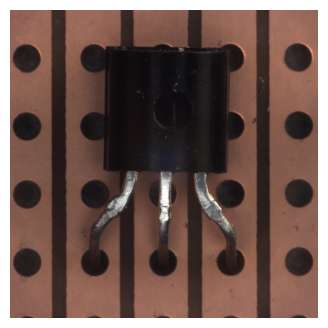

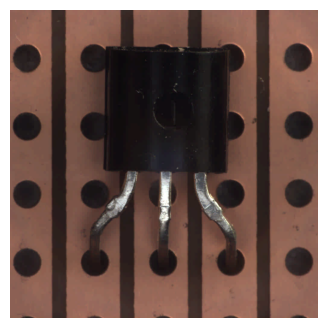

Statistics:
Block size: 8
Quantisation step: 32
Raw image size: 3145728 bytes
Compressed file size: 1181231 bytes
Raw to compressed image ratio: 2.6630929936650833
Bits per pixel: 9.012077331542969
Mean squared error: 6.807010968526204
PSNR: 39.801239104592035


In [31]:
dataset_folder = Path("../mvtec_dataset")

test_images_paths = [
    dataset_folder / "008_capsule.png",
    dataset_folder / "079_hazelnut.png",
    dataset_folder / "143_metal_nut.png",
    dataset_folder / "200_pill.png",
    dataset_folder / "058_transistor.png",
]

settings = inputs(test = True)

for img_path in test_images_paths:
    settings["img_path"] = img_path
    test_pipeline(settings=settings)

### 4.6 Random Input

Encoded image saved to: compressed_images/096_capsule_compressed.json
PASS: The compressed file exists.
PASS: The compressed file is not empty.
Selected Image: 


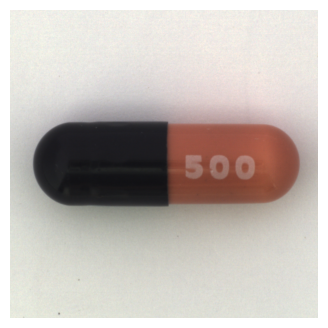

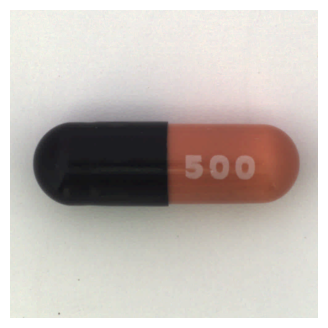

Statistics:
Block size: 8
Quantisation step: 32
Raw image size: 3000000 bytes
Compressed file size: 1000927 bytes
Raw to compressed image ratio: 2.9972215755994194
Bits per pixel: 8.007416
Mean squared error: 10.312167333333333
PSNR: 37.997304092617334


In [32]:
# dataset folder
settings = inputs(read_q_step = True, read_block_size = True)
test_pipeline(settings=settings)

### 4.7 Custom File Input

Encoded image saved to: 000_capsule_compressed.json
PASS: The compressed file exists.
PASS: The compressed file is not empty.
Selected Image: 


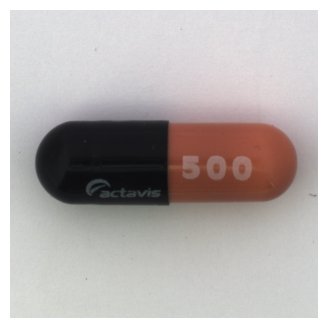

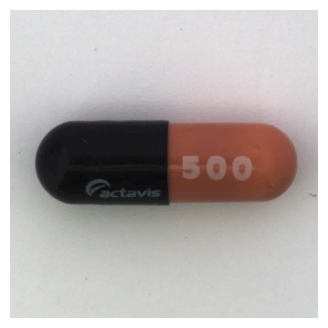

Statistics:
Block size: 8
Quantisation step: 32
Raw image size: 3000000 bytes
Compressed file size: 979868 bytes
Raw to compressed image ratio: 3.0616368735380686
Bits per pixel: 7.838944
Mean squared error: 9.089401666666667
PSNR: 38.54545065260636


In [36]:
# read inputs
settings = inputs(read_img = True, read_output_dir_path = True, read_q_step = True, read_block_size = True)
test_pipeline(settings=settings)

## Section 5: The environment, dependencies, configuration, seed and concise logs.


In [1]:
import sys
import numpy as np
import scipy
import matplotlib

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.14.6 (v3.14.6:c63aec69bd5, Jun 10 2026, 08:07:54) [Clang 21.0.0 (clang-2100.1.1.101)]
NumPy: 2.5.3
SciPy: 1.18.1
Matplotlib: 3.11.2


## Section 6: Timing and memory evidence for one storage or implementation choice.


In [4]:
from pathlib import Path
from PIL import Image
import numpy as np
import random

# Fixed seed for reproducible image selection
random.seed(42)

dataset_dir = Path("../final_dataset")

# Find all images in the training folders
image_paths = sorted(
    path
    for path in dataset_dir.glob("*/train/*")
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if not image_paths:
    raise FileNotFoundError("No images found in the dataset")

# Select one image
image_path = random.choice(image_paths)

# Convert to RGB so both formats store the same data
with Image.open(image_path) as img:
    image_array = np.asarray(img.convert("RGB"))

print("Selected image:", image_path)
print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Memory:", image_array.nbytes / 1024**2, "MiB")


Selected image: ../final_dataset/hazelnut/train/009.png
Shape: (1024, 1024, 3)
Data type: uint8
Memory: 3.0 MiB


In [5]:
import json
import time
import tracemalloc
from pathlib import Path

output_dir = Path("p3_storage_test")
output_dir.mkdir(exist_ok=True)

def measure_save(save_function, file_path):
    tracemalloc.start()

    start = time.perf_counter()
    save_function()
    elapsed = time.perf_counter() - start

    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    file_size = file_path.stat().st_size

    return elapsed, peak_memory / 1024**2, file_size / 1024**2


# Save the same RGB array as NumPy binary
npy_path = output_dir / "image.npy"

npy_results = measure_save(
    lambda: np.save(npy_path, image_array),
    npy_path
)

# Save the same RGB array as JSON
json_path = output_dir / "image.json"

json_results = measure_save(
    lambda: json_path.write_text(
        json.dumps(image_array.tolist()),
        encoding="utf-8"
    ),
    json_path
)

print("Format | Time (s) | Peak Python memory (MiB) | File size (MiB)")
print(f"NPY    | {npy_results[0]:.4f} | {npy_results[1]:.2f} | {npy_results[2]:.2f}")
print(f"JSON   | {json_results[0]:.4f} | {json_results[1]:.2f} | {json_results[2]:.2f}")


Format | Time (s) | Peak Python memory (MiB) | File size (MiB)
NPY    | 0.0029 | 7.24 | 3.00
JSON   | 6.4544 | 105.07 | 14.22


In [6]:
import statistics

npy_times = []
json_times = []

for i in range(5):
    npy_result = measure_save(
        lambda: np.save(npy_path, image_array),
        npy_path
    )
    npy_times.append(npy_result[0])

    json_result = measure_save(
        lambda: json_path.write_text(
            json.dumps(image_array.tolist()),
            encoding="utf-8"
        ),
        json_path
    )
    json_times.append(json_result[0])

print("NPY times:", [round(t, 3) for t in npy_times])
print("JSON times:", [round(t, 3) for t in json_times])

print(f"NPY median: {statistics.median(npy_times):.4f} seconds")
print(f"JSON median: {statistics.median(json_times):.4f} seconds")


NPY times: [0.004, 0.001, 0.002, 0.002, 0.002]
JSON times: [6.502, 6.223, 6.542, 6.199, 6.186]
NPY median: 0.0018 seconds
JSON median: 6.2230 seconds


## Section 7: Failure handling for a missing input, a digest mismatch, an invalid shape and an interrupted run.


Testing Empty Input

In [37]:
## empty input
settings = inputs(test=True)

empty_images = [
    np.empty((0,0), dtype=uint8),      # Empty 2D image
    np.empty((0,0,0), dtype=uint8),    # Empty 3D image 
    np.empty((0,1,2), dtype=uint8),    # Zero Height 3D
    np.empty((0,1), dtype=uint8),      # Zero Height 2D
    np.empty((2,0,1), dtype=uint8),    # Zero Width 3D
    np.empty((2,0), dtype=uint8),      # Zero Width 2D
    np.empty((2,1,0), dtype=uint8),    # Zero Channel
]

count=1
for empty in empty_images:
    settings["img_path"] = ""
    try:
        test_pipeline(settings=settings, image=empty, output_filename=f"empty_{count}_compressed")
    
    except ValueError as error:
        print(f"PASS: {empty.shape} rejected - {error}")
    else:
        raise AssertionError(f"FAIL: empty inputs {empty.shape} was accepted")

PASS: (0, 0) rejected - Input should not be empty
PASS: (0, 0, 0) rejected - Input must be 2D or 3D with atleast 1 channel
PASS: (0, 1, 2) rejected - Input should not be empty
PASS: (0, 1) rejected - Input should not be empty
PASS: (2, 0, 1) rejected - Input should not be empty
PASS: (2, 0) rejected - Input should not be empty
PASS: (2, 1, 0) rejected - Input must be 2D or 3D with atleast 1 channel


In [49]:
from tempfile import TemporaryDirectory
from unittest.mock import patch

def verify_sha256(path, expected_digest):
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual != expected_digest:
        raise ValueError("SHA-256 digest mismatch")


with TemporaryDirectory() as folder:
    temp = Path(folder)

    settings = {
        "img_path": temp / "missing.png",
        "output_dir": temp,
        "q_step": 32,
        "block_size": 8,
    }

    # 1. Missing input
    try:
        test_pipeline(settings)
        print("FAIL: Missing input accepted")
    except FileNotFoundError:
        print("PASS: Missing input rejected")

    # 2. Invalid image shape
    try:
        test_pipeline(
            settings,
            image=np.zeros((8,), dtype=np.uint8)
        )
        print("FAIL: Invalid shape accepted")
    except ValueError:
        print("PASS: Invalid shape rejected")

    # 3. SHA-256 digest mismatch
    manifest = json.loads(
        Path("dataset_manifest.json").read_text()
    )
    entry = manifest[0]

    original = Path("../mvtec_dataset") / entry["path"]
    altered = temp / "altered.png"

    data = bytearray(original.read_bytes())
    data[0] ^= 1  # Modify one byte, preserving file size
    altered.write_bytes(data)

    try:
        verify_sha256(altered, entry["sha256"])
        print("FAIL: Digest mismatch undetected")
    except ValueError:
        print("PASS: Digest mismatch detected")

    # 4. Simulated interruption during JSON writing
    def interrupt_write(data, file, **kwargs):
        file.write('{"incomplete":')
        raise KeyboardInterrupt("Simulated interruption")

    output = temp / "interrupted.json"

    with patch("codec.json.dump", side_effect=interrupt_write):
        try:
            test_pipeline(
                settings,
                image=np.zeros((8, 8, 3), dtype=np.uint8),
                output_filename="interrupted.json",
            )
        except KeyboardInterrupt:
            print("PASS: Interruption propagated")

    if output.exists():
        print("FAIL: Incomplete output file remains")
    else:
        print("PASS: No incomplete output file remains")

PASS: Missing input rejected
PASS: Invalid shape rejected
PASS: Digest mismatch detected
PASS: Interruption propagated
PASS: No incomplete output file remains


## Section 8: Known limitations, who maintains it, who did what, and the generative-AI declaration.


### Known limitations:

The project currently has the following known limitations:

- The storage performance experiment was conducted using one RGB image, so its results may not generalise to the entire dataset.
- The storage comparison measures raw image representations rather than the compressed output of the P2 codec.

### Maintenance

The project is jointly maintained by the two group members. Both are responsible for reviewing and maintaining their respective implementations and ensuring the integrated pipeline works correctly.

### Division of work
Akanksha: Dataset schema, quality-assurance report, SHA-256 manifest, end-to-end pipeline, and concise logging.
Filza: Environment, dependencies, configuration, random seed, timing and memory measurements, failure-handling tests, limitations, contribution documentation, and AI declaration.


### Generative-AI declaration
ChatGPT (OpenAI) was used to help interpret assignment requirements, plan the implementation, and develop code for the timing and memory experiment. The code was executed and tested locally, and the results were verified by the group members. The final implementation and analysis remain the responsibility of the group members.
